# Data Cleaning    

In [124]:
# Import necessary libraries
import pandas as pd
import numpy as np
import hashlib

import matplotlib.pyplot as plt
import seaborn as sns

import shap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve





In [125]:
import os

path = r"D:/Ms   DSA/Module 4/Applied Machine Learning/Capstone project/Raw data"

print(os.path.exists(path))

if os.path.exists(path):
    print(os.listdir(path))

False


In [126]:
data = pd.read_csv(
    r"D:/Ms DSA/Module 4/Applied Machine Learning/Capstone project/Raw data/fao_2021_2026_applicants.csv",
    encoding="cp1252"
)

In [127]:
data

,Student Number,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,152569,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13T11:52:55,Not Approved
1,226514,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13T12:35:40,Approved
2,226959,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:32:19,Approved
3,226959,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:40:30,Not Approved
4,227220,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04T10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,146420,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30T16:15:44,Approved
4172,145248,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02T09:21:37,Approved
4173,146327,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02T17:47:34,Not Approved
4174,145402,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04T17:19:56,Approved


Let encode the admission numbers and save it

In [128]:
data["ID"] = data['Student Number'].apply(
    lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:12]
)
data.drop(columns=['Student Number'], inplace=True)

anon_id = data.pop("ID")
data.insert(0, "ID", anon_id)

In [129]:
data

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13T11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13T12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04T10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30T16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02T09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02T17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04T17:19:56,Approved


In [130]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             4176 non-null   str  
 1   Gender         4176 non-null   str  
 2   High School    4162 non-null   str  
 3   Mean Grade     4154 non-null   str  
 4   O LEVEL YEAR   4176 non-null   int64
 5   County         4176 non-null   str  
 6   Country        4176 non-null   str  
 7   Parent Status  657 non-null    str  
 8   Intake         4176 non-null   str  
 9   Course         4176 non-null   str  
 10  Siblings       4176 non-null   str  
 11  Date Applied   4176 non-null   str  
 12  Status         4176 non-null   str  
dtypes: int64(1), str(12)
memory usage: 424.3 KB


In [131]:
# Let save the dataset

data.to_csv('../data/fao_2021_2026_applicants_cleaned.csv', index=False)



# Data Cleaning 

In [132]:
fa = pd.read_csv('../data/fao_2021_2026_applicants_cleaned.csv')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13T11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13T12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04T10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30T16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02T09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02T17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04T17:19:56,Approved


Let do data inspection


In [133]:
#data inspection on Info, is null, describe, shape, columns, head, tail, columns, dtypes, unique values,

fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             4176 non-null   str  
 1   Gender         4176 non-null   str  
 2   High School    4162 non-null   str  
 3   Mean Grade     4154 non-null   str  
 4   O LEVEL YEAR   4176 non-null   int64
 5   County         4176 non-null   str  
 6   Country        4176 non-null   str  
 7   Parent Status  657 non-null    str  
 8   Intake         4176 non-null   str  
 9   Course         4176 non-null   str  
 10  Siblings       4176 non-null   str  
 11  Date Applied   4176 non-null   str  
 12  Status         4176 non-null   str  
dtypes: int64(1), str(12)
memory usage: 424.3 KB


In [134]:
fa.isnull().sum()

ID                  0
Gender              0
High School        14
Mean Grade         22
O LEVEL YEAR        0
County              0
Country             0
Parent Status    3519
Intake              0
Course              0
Siblings            0
Date Applied        0
Status              0
dtype: int64

In [135]:
fa.shape

(4176, 13)

In [136]:
columns = [
    'Gender',
    'High School',
    'Mean Grade',
    'O LEVEL YEAR',
    'County',
    'Country',
    'Parent Status',
    'Intake',
    'Course',
    'Siblings',
    'Date Applied',
    'Status'
]

for col in columns:
    print(f"\n{'='*50}")
    print(f"Value Counts for: {col}")
    print(f"{'='*50}")
    print(fa[col].value_counts())


Value Counts for: Gender
Gender
Male      2271
Female    1905
Name: count, dtype: int64

Value Counts for: High School
High School
Alliance High School                89
Strathmore School                   85
Mangu High School                   74
Maseno School                       60
Nairobi School                      56
                                    ..
Kiserian Junior Seminary             1
NJABINI BOYS HIGH SCHOOL             1
Mahad Academy School                 1
St.John Paul II Mixed Sec School     1
NorthGate School                     1
Name: count, Length: 769, dtype: int64

Value Counts for: Mean Grade
Mean Grade
B+          831
B           787
B-          635
A-          628
C+          450
A           351
C           306
A LEVELS    119
C-           36
Diploma       3
E             2
D+            2
A Levels      2
D             1
SBS           1
Name: count, dtype: int64

Value Counts for: O LEVEL YEAR
O LEVEL YEAR
2023    828
2024    812
2025    774
2022    473


In [137]:

for col in columns:
    counts = fa[col].value_counts().reset_index()
    counts.columns = [col, 'Count']
    print(f"\n{col}")
    print(counts)



Gender
   Gender  Count
0    Male   2271
1  Female   1905

High School
                          High School  Count
0                Alliance High School     89
1                   Strathmore School     85
2                   Mangu High School     74
3                       Maseno School     60
4                      Nairobi School     56
..                                ...    ...
764          Kiserian Junior Seminary      1
765          NJABINI BOYS HIGH SCHOOL      1
766              Mahad Academy School      1
767  St.John Paul II Mixed Sec School      1
768                  NorthGate School      1

[769 rows x 2 columns]

Mean Grade
   Mean Grade  Count
0          B+    831
1           B    787
2          B-    635
3          A-    628
4          C+    450
5           A    351
6           C    306
7    A LEVELS    119
8          C-     36
9     Diploma      3
10          E      2
11         D+      2
12   A Levels      2
13          D      1
14        SBS      1

O LEVEL YEAR
  

Let change the date applied column to datetime format

In [138]:
#fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='coerce')
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], format='ISO8601')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13 11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30 16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02 09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02 17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04 17:19:56,Approved


Let check for duplicate values

In [139]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(1138)

We have 1138 duplicated values with both the ID, COurse and Status. 
We will go ahead and remove duplicate where ID, Course and Status are the same while keeping one occurance.

In [140]:
fa = fa.drop_duplicates(
    subset=["ID", "Course", "Status"], 
    keep='first'
    )

In [141]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(0)

Let check if we still have duplicated values where ID and course are the same but different Status: 

In [142]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(537)

We still have 537 duplicated values with the same id and course but different status. 

We will remove duplicates where Status = Not approved and keep the ones which is approved. 

In [143]:
fa = fa.sort_values(by='Status', ascending=True)
fa = fa.drop_duplicates(subset=['ID', 'Course'], keep='first')

In [144]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(0)

Let tret the missingness in Parent Status

In [145]:
fa['Parent Status'] = fa['Parent Status'].fillna('Both Parents')
fa['Parent Status'].value_counts()

Parent Status
Both Parents       2119
Father Deceased     241
Mother Deceased      95
Orphan               46
Name: count, dtype: int64

In [146]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1997 to 686
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 273.5 KB


Let remove the international students from our datasets

In [147]:
print(fa['Date Applied'].min()) 
print(fa['Date Applied'].max())

2021-01-02 13:02:32
2026-10-21 19:51:38


In [148]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1997 to 686
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 273.5 KB


In [149]:
# Let create a new column called "Application Year" that extracts the year from the "Date Applied" column.
fa['Apply_Year'] = fa['Date Applied'].dt.year
fa['Apply_Month'] = fa['Date Applied'].dt.month
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month
1997,ebdbd5cc54e1,Male,Strathmore School,A,2024,Kiambu,Kenya,Both Parents,Apr-25,Bachelor of Business Science in Financial Econ...,,2025-02-21 11:15:30,Approved,2025,2
2181,5131d3c3fe54,Male,Mangu High School,A-,2022,Kiambu,Kenya,Both Parents,Apr-23,Bachelor of Business Science in Financial Econ...,,2025-10-28 13:06:19,Approved,2025,10
2179,84e758506c7c,Male,Chianda High School,C,2024,Nairobi,Kenya,Father Deceased,Sept-25,Diploma in International Relations FT,,2025-09-04 16:33:01,Approved,2025,9
2174,1fef959fb467,Male,Strathmore School,B,2020,Kajiado,Kenya,Both Parents,Sept-21,Bsc. Computer Networks and Cybersecurity,,2025-10-03 12:01:00,Approved,2025,10
2167,390fd02cbbb4,Male,Nova Pioneer Boys High School Tatu,B,2023,Nairobi,Kenya,Both Parents,Jul-24,Bachelor of Science in Supply Chain and Operat...,,2025-10-22 11:36:45,Approved,2025,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2319,58430f6a7869,Male,Homa - Bay High Sch,B,2019,Homa Bay,Kenya,Both Parents,Sept-25,Certified Public Accountant,,2025-09-12 21:17:44,Not Approved,2025,9
677,cd879b7144d7,Male,Matongo Boys High School,B,2025,Siaya,Kenya,Both Parents,Sept-26,Diploma in Business Creation and Entrepreneurs...,,2026-08-25 10:28:21,Not Approved,2026,8
682,65fa026a842d,Male,Christ The King Academy,B,2025,Kajiado,Kenya,Both Parents,Jul-26,Bachelor of Financial Services,,2026-09-09 11:02:23,Not Approved,2026,9
2308,cb75066efb56,Male,Highway Secondary School,A-,2021,Nairobi,Kenya,Mother Deceased,Jul-23,Bachelor of Laws,,2025-07-23 05:10:30,Not Approved,2025,7


In [150]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1997 to 686
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
 13  Apply_Year     2501 non-null   int32         
 14  Apply_Month    2501 non-null   int32         
dtypes: datetime64[us](1), int32(2), int

In [151]:
fa.to_csv('../data/fa_final.csv', index=False) 

# Exploratory Data Analysics

In [152]:
fa = pd.read_csv('../data/fa_final.csv')

In [153]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2501 entries, 0 to 2500
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2501 non-null   str  
 1   Gender         2501 non-null   str  
 2   High School    2494 non-null   str  
 3   Mean Grade     2485 non-null   str  
 4   O LEVEL YEAR   2501 non-null   int64
 5   County         2501 non-null   str  
 6   Country        2501 non-null   str  
 7   Parent Status  2501 non-null   str  
 8   Intake         2501 non-null   str  
 9   Course         2501 non-null   str  
 10  Siblings       2501 non-null   str  
 11  Date Applied   2501 non-null   str  
 12  Status         2501 non-null   str  
 13  Apply_Year     2501 non-null   int64
 14  Apply_Month    2501 non-null   int64
dtypes: int64(3), str(12)
memory usage: 293.2 KB


In [154]:
fa.isnull().sum()

ID                0
Gender            0
High School       7
Mean Grade       16
O LEVEL YEAR      0
County            0
Country           0
Parent Status     0
Intake            0
Course            0
Siblings          0
Date Applied      0
Status            0
Apply_Year        0
Apply_Month       0
dtype: int64

In [155]:
fa = fa[fa['Country']=='Kenya']

In [156]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2271 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2271 non-null   str  
 1   Gender         2271 non-null   str  
 2   High School    2264 non-null   str  
 3   Mean Grade     2265 non-null   str  
 4   O LEVEL YEAR   2271 non-null   int64
 5   County         2271 non-null   str  
 6   Country        2271 non-null   str  
 7   Parent Status  2271 non-null   str  
 8   Intake         2271 non-null   str  
 9   Course         2271 non-null   str  
 10  Siblings       2271 non-null   str  
 11  Date Applied   2271 non-null   str  
 12  Status         2271 non-null   str  
 13  Apply_Year     2271 non-null   int64
 14  Apply_Month    2271 non-null   int64
dtypes: int64(3), str(12)
memory usage: 283.9 KB


--- Missing Value Summary ---
             Missing Count  Percentage (%)
High School              7        0.308234
Mean Grade               6        0.264201

--- Target Variable ('Status') Distribution ---
              Count  Percentage (%)
Status                             
Approved       1264         55.6583
Not Approved   1007         44.3417


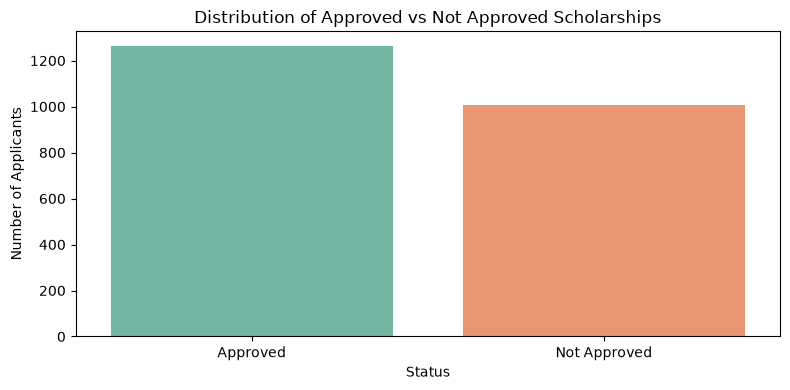

In [157]:
print("--- Missing Value Summary ---")
missing = fa.isnull().sum()
missing_pct = (missing / len(fa)) * 100
missing_fa = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print(missing_fa[missing_fa['Missing Count'] > 0])

print("\n--- Target Variable ('Status') Distribution ---")
status_counts = fa['Status'].value_counts(dropna=False)
status_pct = fa['Status'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': status_counts, 'Percentage (%)': status_pct}))

# Plot Target Distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=fa, x='Status', hue='Status', palette='Set2')
plt.title('Distribution of Approved vs Not Approved Scholarships')
plt.ylabel('Number of Applicants')
plt.tight_layout()
plt.show()

Let observe the gender distribution per scholarship distribution

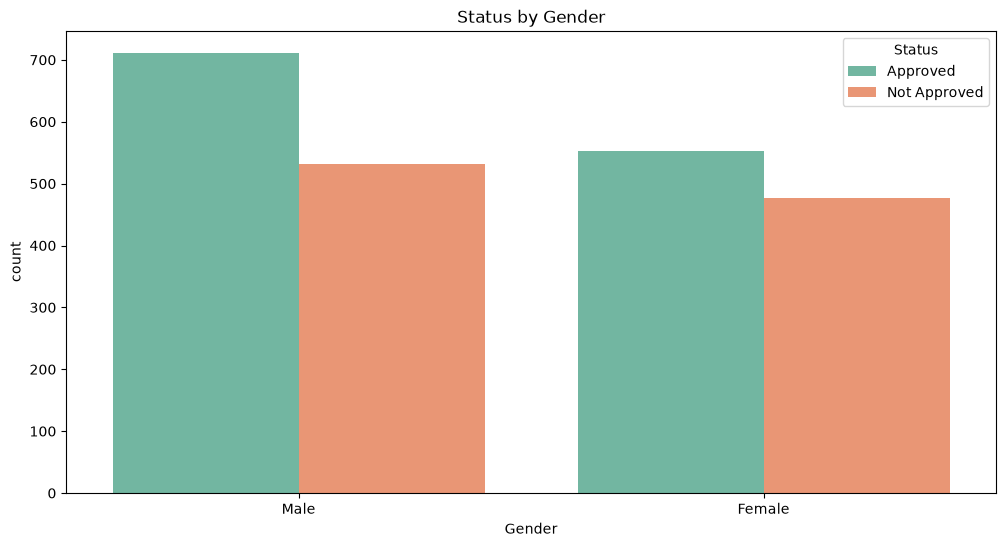

In [158]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=fa, 
    x='Gender', 
    hue='Status', 
    palette='Set2',
)
plt.title('Status by Gender')
plt.show()

Let observe the grade status awards

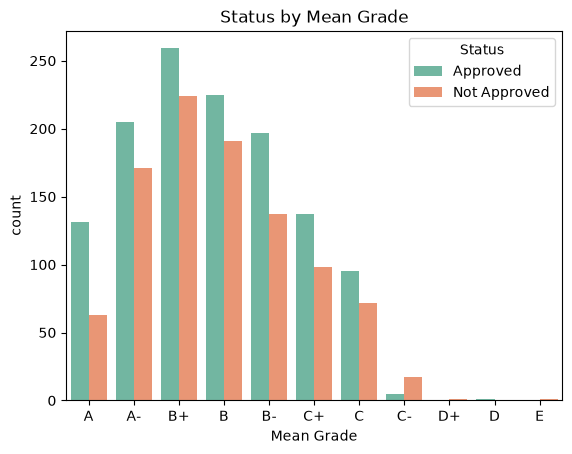

In [159]:
grade_order = ['A', 'A-', 'B+', 'B', 'B-', 'C+', 'C', 'C-', 'D+', 'D', 'D-', 'E']
# Filter order to only available grades in dataset
existing_grades = [g for g in grade_order if g in fa['Mean Grade'].unique()]
sns.countplot(
    data=fa, 
    x='Mean Grade', 
    hue='Status', 
    order=existing_grades, 
    palette='Set2'
)
plt.title('Status by Mean Grade')
plt.show()

Let plot the parent status awards 

First we will go ahead and check how many were approved and how many were not and compute its percentage ratio.

In [160]:
parent_counts = fa['Parent Status'].value_counts()
Approved_counts = fa[fa['Status'] == 'Approved']['Parent Status'].value_counts()
Not_Approved_counts = fa[fa['Status'] == 'Not Approved']['Parent Status'].value_counts()
approved_pct = (Approved_counts / parent_counts) * 100
not_approved_pct = (Not_Approved_counts / parent_counts) * 100 

pd.DataFrame(
    {
        'Parent Status': parent_counts, 
        'Approved': Approved_counts, 
        'Not Approved': Not_Approved_counts,
        'Approved %': approved_pct,
        'Not Approved %': not_approved_pct
    })

,Parent Status,Approved,Not Approved,Approved %,Not Approved %
Parent Status,,,,,
Both Parents,1919,1061,858,55.289213,44.710787
Father Deceased,222,130,92,58.558559,41.441441
Mother Deceased,87,49,38,56.321839,43.678161
Orphan,43,24,19,55.813953,44.186047


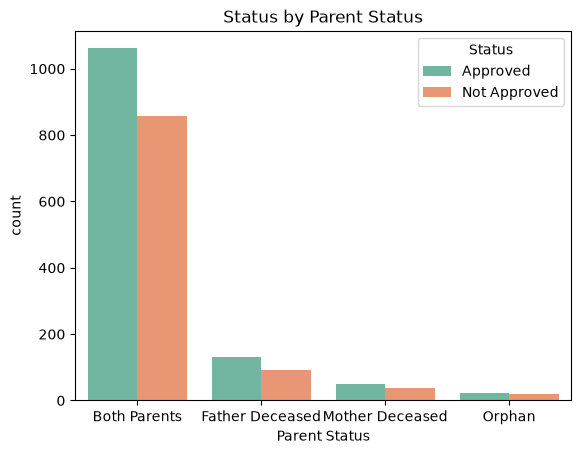

In [161]:
sns.countplot(
    data=fa, 
    x='Parent Status', 
    hue='Status',
    palette='Set2'
)
plt.title('Status by Parent Status')
plt.show()

Let analyse the top high schools to be awarded a form of scholarship

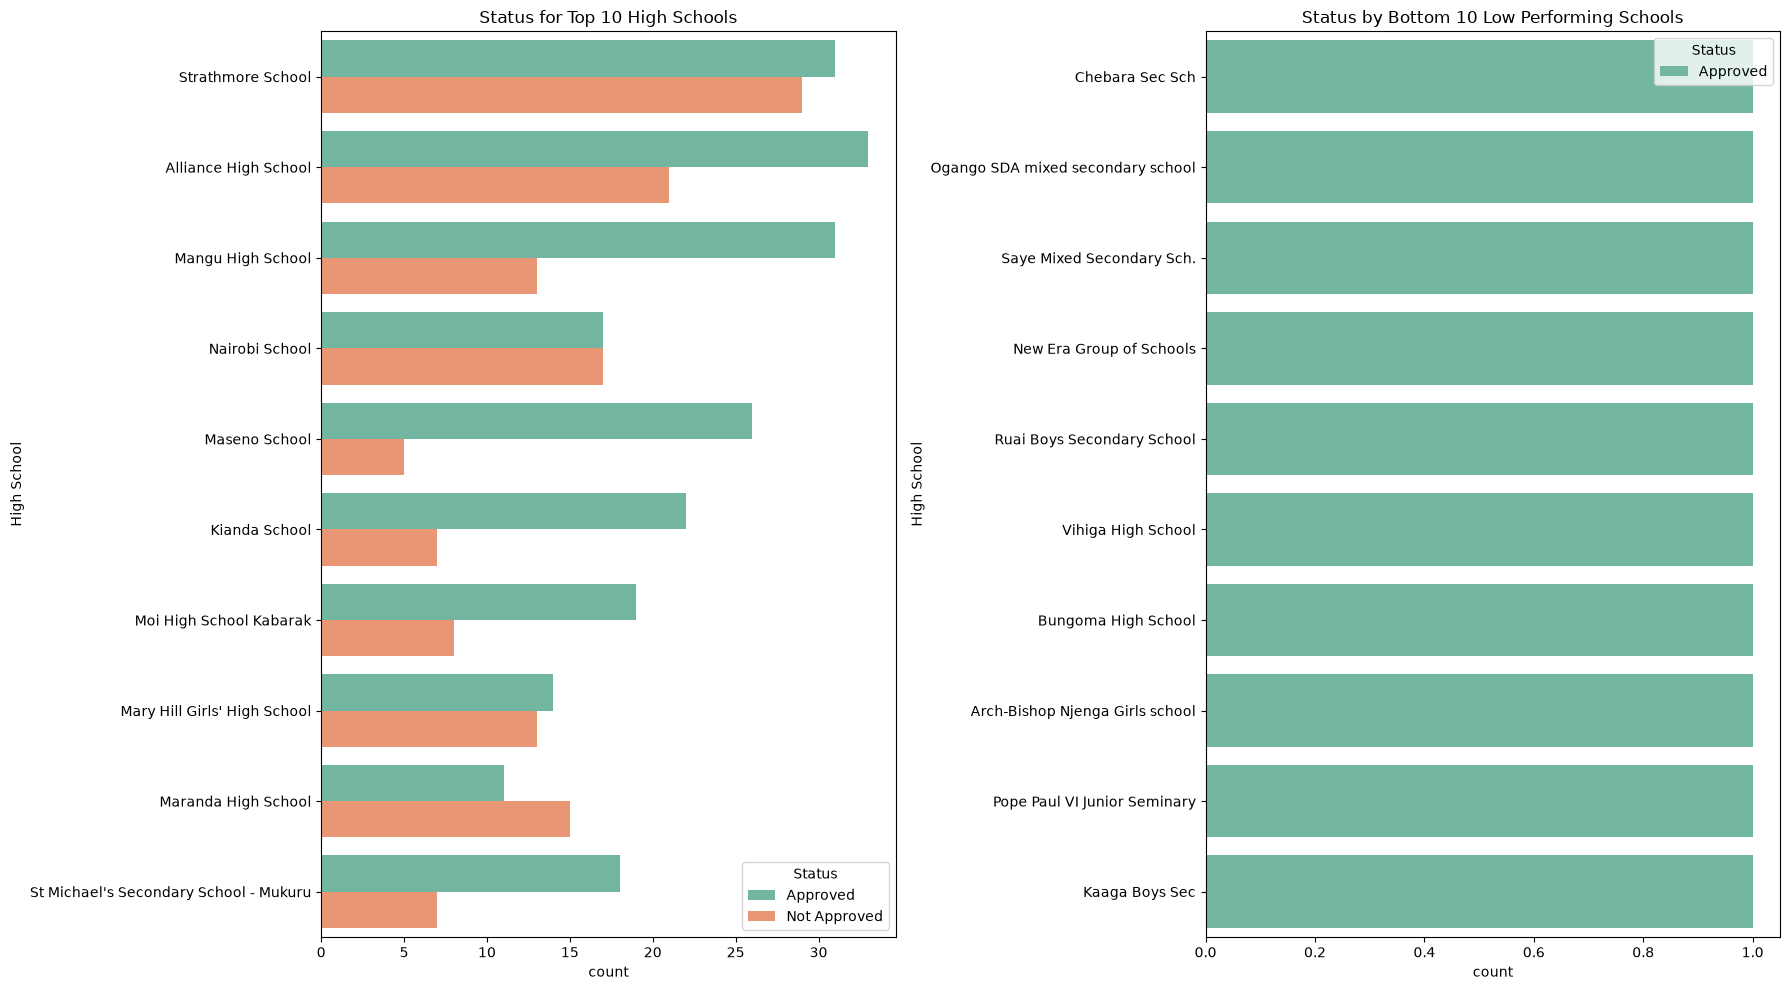

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

top_schools = fa['High School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(top_schools)], 
    y='High School',
    hue='Status',
    order=top_schools,
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Status for Top 10 High Schools')

bottom_schools = fa['High School'].value_counts().nsmallest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(bottom_schools)], 
    y='High School',
    hue='Status',
    order=bottom_schools,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('Status by Bottom 10 Low Performing Schools')

plt.tight_layout()
plt.show()


LEt observe the top 5 applied course. 

In [163]:
fa['Course'].value_counts().nlargest()



Course
Bachelor of Science in Informatics and Computer Science    326
Bachelor of Commerce                                       301
Bachelor of Business Information Technology                252
Certified Public Accountant                                179
Diploma in Business Information Technology                 169
Name: count, dtype: int64

We will add the school/faculty type

In [164]:
faculty = pd.read_csv('../data/su_faculty.csv')
faculty.head()

,#,Course,School
0,1,ACCA Diploma,SIMT
1,2,Association of Chartered Certified Accountants,SIMT
2,3,Bachelor of Arts Communication,SHSS
3,4,Bachelor of Arts Development Studies and Philo...,SHSS
4,5,Bachelor of Arts International Studies,SHSS


Let use the left merge to add the School/Faculty of our courses before

In [165]:
fa = fa.merge(
    faculty[['Course', 'School']],
    on='Course',
    how='left'
)

In [166]:
fa.head()

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School
0,ebdbd5cc54e1,Male,Strathmore School,A,2024,Kiambu,Kenya,Both Parents,Apr-25,Bachelor of Business Science in Financial Econ...,,2025-02-21 11:15:30,Approved,2025,2,SIMS
1,5131d3c3fe54,Male,Mangu High School,A-,2022,Kiambu,Kenya,Both Parents,Apr-23,Bachelor of Business Science in Financial Econ...,,2025-10-28 13:06:19,Approved,2025,10,SIMS
2,84e758506c7c,Male,Chianda High School,C,2024,Nairobi,Kenya,Father Deceased,Sept-25,Diploma in International Relations FT,,2025-09-04 16:33:01,Approved,2025,9,SIMT
3,1fef959fb467,Male,Strathmore School,B,2020,Kajiado,Kenya,Both Parents,Sept-21,Bsc. Computer Networks and Cybersecurity,,2025-10-03 12:01:00,Approved,2025,10,SCES
4,390fd02cbbb4,Male,Nova Pioneer Boys High School Tatu,B,2023,Nairobi,Kenya,Both Parents,Jul-24,Bachelor of Science in Supply Chain and Operat...,,2025-10-22 11:36:45,Approved,2025,10,SBS


Now that we have the School Categories, let plot it and see how it behaved. 

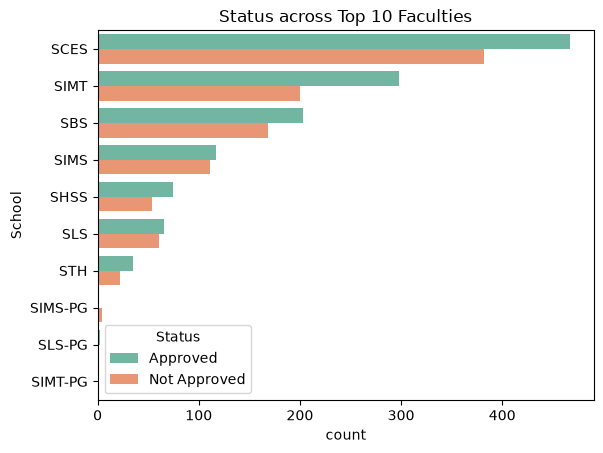

In [167]:
top_faculties = fa['School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['School'].isin(top_faculties)], 
    y='School', 
    hue='Status', 
    order=top_faculties, 
    palette='Set2'
)
plt.title('Status across Top 10 Faculties')
plt.show()

Let now observe the volume of application over time.

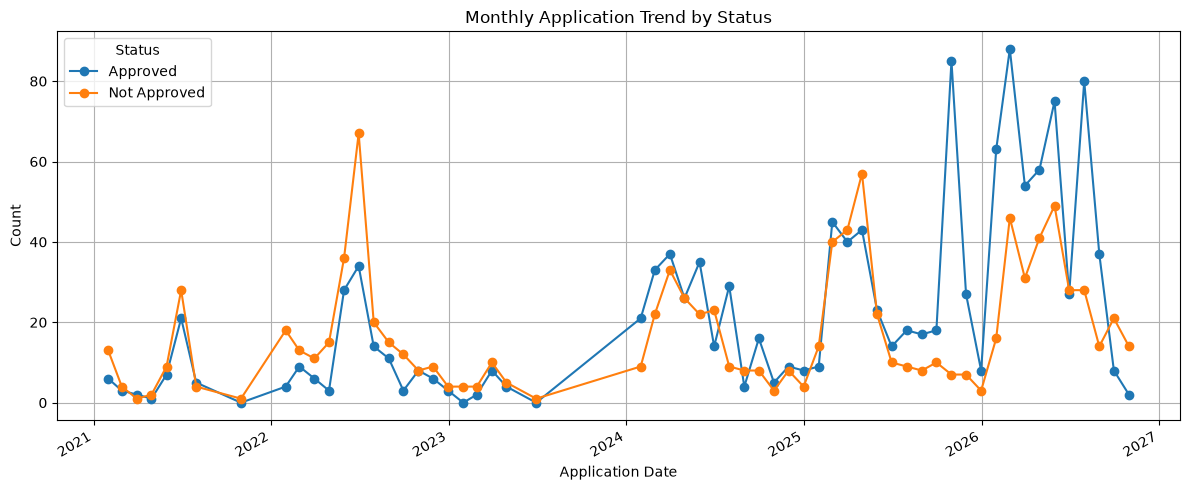

In [168]:
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='raise')

fa_data_time = (
    fa.set_index('Date Applied')
      .groupby([pd.Grouper(freq='ME'), 'Status'])
      .size()
      .unstack(fill_value=0)
)

fa_data_time.plot(kind='line', marker='o', figsize=(12, 5))
plt.title('Monthly Application Trend by Status')
plt.xlabel('Application Date')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

# Pre-treatment for Machine Learning

Let prepare the Features engineers 

1. We shall convert the grade in numerical values

In [169]:
grade_map = { # Let try giving B+ and above the same result. 
    'A': 10,
    'A-': 9,
    'B+': 8,
    'B': 7,
    'B-': 6,
    'C+': 5,
    'A LEVELS': 4,
    'DIPLOMA': 3,
    'C': 2,
    'C-': 1, #From here I decided to give all the grades below C- a value of 0 since they are not considered good grades.
    'D+': 0,
    'D': 0,
    'D-': 0,
    'E': 0
}

fa['Mean Grade'] = fa['Mean Grade'].astype(str).str.strip().str.upper()
fa['mean_grade_score'] = (
    fa['Mean Grade']
    .astype(str)
    .str.strip()
    .str.upper()
    .map(grade_map)
)

In [170]:
fa['mean_grade_score'].value_counts().sort_index()

mean_grade_score
0.0       3
1.0      22
2.0     167
3.0       1
4.0      34
5.0     235
6.0     334
7.0     416
8.0     483
9.0     376
10.0    194
Name: count, dtype: int64

<Axes: xlabel='mean_grade_score'>

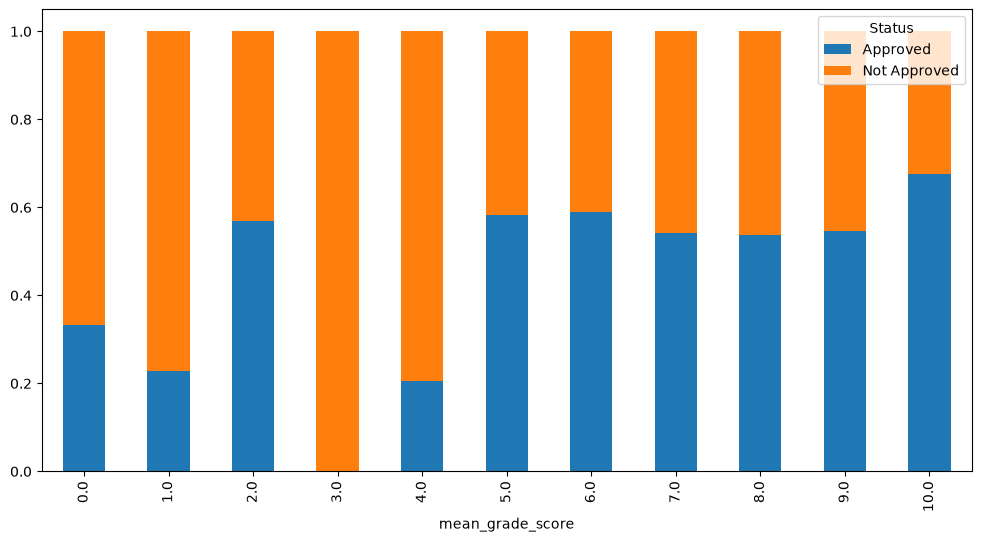

In [192]:
Table = fa[['mean_grade_score', 'Status']]
value_counts = Table.groupby('mean_grade_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, figsize=(12, 6))

In [176]:
fa.nunique()

ID                  2134
Gender                 2
High School          656
Mean Grade            13
O LEVEL YEAR          29
County                47
Country                1
Parent Status          4
Intake                71
Course                36
Siblings               1
Date Applied        2266
Status                 2
Apply_Year             6
Apply_Month           12
School                12
mean_grade_score      11
dtype: int64

2. Let now create county vulnerability score

In [194]:
county_vulnerability = pd.read_csv('../data/County_GVA_Contribution_Ranked_2019_2023.csv')
county_vulnerability

,Rank,County,2019 (%),2020 (%),2021 (%),2022 (%),2023 (%),5-Year Avg (%),County Rate,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,1,Nairobi,27.80%,27.20%,27.20%,27.70%,27.40%,27.50%,1,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Kiambu,5.70%,5.60%,5.60%,5.60%,5.50%,5.60%,1,NaN,NaN,NaN,NaN,NaN,NaN
2,3,Nakuru,4.90%,4.90%,5.20%,5.20%,5.70%,5.20%,1,NaN,NaN,NaN,NaN,NaN,NaN
3,4,Mombasa,5.00%,4.80%,4.80%,4.80%,4.80%,4.80%,1,NaN,NaN,NaN,NaN,NaN,NaN
4,5,Meru,3.30%,3.30%,3.40%,3.30%,3.50%,3.40%,1,NaN,NaN,NaN,NaN,NaN,NaN
5,6,Machakos,3.20%,3.10%,3.20%,3.20%,3.20%,3.20%,2,NaN,NaN,NaN,NaN,NaN,NaN
6,7,Kisumu,2.50%,2.50%,2.50%,2.50%,2.50%,2.50%,2,NaN,NaN,NaN,NaN,NaN,NaN
7,8,Uasin Gishu,2.40%,2.30%,2.40%,2.40%,2.50%,2.40%,2,NaN,NaN,NaN,NaN,NaN,NaN
8,9,Kakamega,2.20%,2.20%,2.20%,2.20%,2.10%,2.20%,2,NaN,NaN,NaN,NaN,NaN,NaN
9,10,Kilifi,2.10%,2.00%,2.10%,2.10%,2.10%,2.10%,2,NaN,NaN,NaN,NaN,NaN,NaN


In [195]:
fa['County'] = fa['County'].str.strip()
county_vulnerability['County'] = county_vulnerability['County'].str.strip()

In [196]:
fa = fa.merge(
    county_vulnerability[['County', 'County Rate']],
    on='County',
    how='left'
)

In [197]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2271 entries, 0 to 2270
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                2271 non-null   str           
 1   Gender            2271 non-null   str           
 2   High School       2264 non-null   str           
 3   Mean Grade        2265 non-null   str           
 4   O LEVEL YEAR      2271 non-null   int64         
 5   County            2271 non-null   str           
 6   Country           2271 non-null   str           
 7   Parent Status     2271 non-null   str           
 8   Intake            2271 non-null   str           
 9   Course            2271 non-null   str           
 10  Siblings          2271 non-null   str           
 11  Date Applied      2271 non-null   datetime64[us]
 12  Status            2271 non-null   str           
 13  Apply_Year        2271 non-null   int64         
 14  Apply_Month       2271 non-null   i

In [208]:
county_null = fa.loc[fa['County Rate'].isna(), 'County']
county_null.value_counts()

Series([], Name: count, dtype: int64)

We have identified international students who applied for scholarship we are going to drop them since our analysis will be Kenya Focus. 


In [209]:
fa = fa[fa['County'] != 'INTERNATIONAL STUDENT'].copy()
fa['County'].value_counts().sort_index()

County
Baringo             10
Bomet                5
Bungoma             51
Busia               36
Elgeyo Marakwet      2
Embu                13
Garissa              2
Homa Bay            49
Isiolo               3
Kajiado             93
Kakamega            82
Kericho             22
Kiambu             197
Kilifi              12
Kirinyaga           16
Kisii               60
Kisumu              90
Kitui               40
Kwale                6
Laikipia            16
Lamu                 1
Machakos            83
Makueni             44
Mandera              4
Marsabit             6
Meru                24
Migori              30
Mombasa             47
Murang'a            41
Nairobi            781
Nakuru              59
Nandi               13
Narok                9
Nyamira             18
Nyandarua           20
Nyeri               43
Samburu             23
Siaya               93
Taita Taveta        17
Tana River           7
Tharaka Nithi        8
Trans Nzoia         30
Turkana              3
Uasi

<Axes: xlabel='County Rate'>

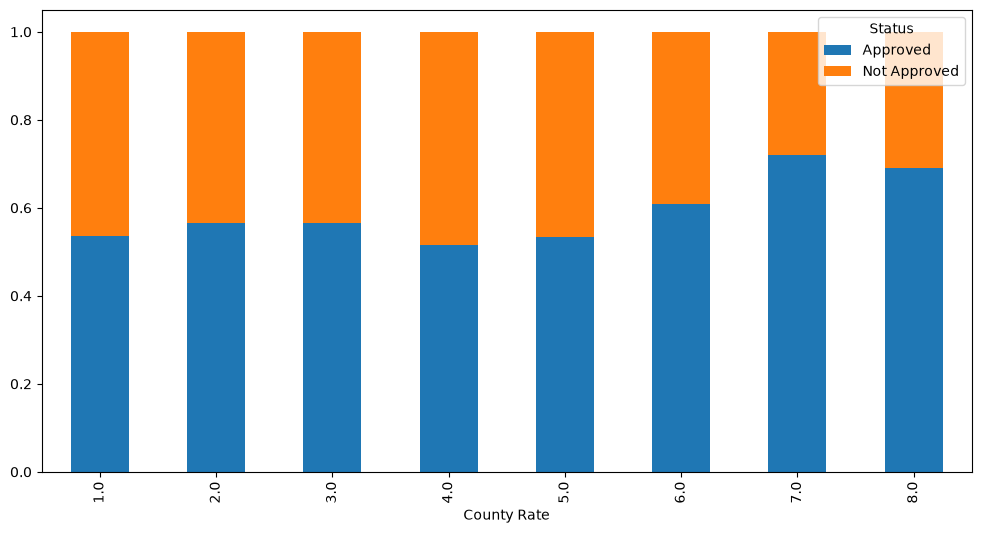

In [210]:
# Show the award 
Table = fa[['County Rate', 'Status']]
value_counts = Table.groupby('County Rate')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

In [211]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2269 entries, 0 to 2270
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                2269 non-null   str           
 1   Gender            2269 non-null   str           
 2   High School       2262 non-null   str           
 3   Mean Grade        2263 non-null   str           
 4   O LEVEL YEAR      2269 non-null   int64         
 5   County            2269 non-null   str           
 6   Country           2269 non-null   str           
 7   Parent Status     2269 non-null   str           
 8   Intake            2269 non-null   str           
 9   Course            2269 non-null   str           
 10  Siblings          2269 non-null   str           
 11  Date Applied      2269 non-null   datetime64[us]
 12  Status            2269 non-null   str           
 13  Apply_Year        2269 non-null   int64         
 14  Apply_Month       2269 non-null   int64 